### Who benefits from grocery offer?

the bis is deciding whom to offer a $5 grocery discount. Sending it to frequent shoppers is easy. But some would have bought anyway. We want to find customers whose spending actually increases because of the offer.

One row represents one customer with a complete 30-day follow-up. We randomly assign the offer to 20% of 6,000 eligible customers and measure merchandise spending before campaign costs. The effect is for offering the discount, whether or not someone redeems it.

Meta-learners complement this randomized study; they do not replace randomization. EconML organizes the models for all three. The outcome models use boosted trees: a sequence of small trees that correct earlier prediction errors. X uses Ridge, a linear model with a penalty that discourages unstable coefficients, to learn a smoother effect pattern.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyClassifier
from econml.metalearners import SLearner, TLearner, XLearner

# Case-study customers. All inputs precede the offer.
rng = np.random.default_rng(42)
n = 6000
X = np.column_stack([rng.uniform(0, 5, n), rng.uniform(0, 1, n)])
T = rng.binomial(1, 0.20, n)  # Randomly offer the coupon to 20%.
true_effect = 10 - 2 * X[:, 0]  # Teaching truth; never passed to a learner.
Y = 60 + 5 * X[:, 0] + 8 * X[:, 1] + T * true_effect + rng.normal(0, 8, n)
data = pd.DataFrame({"prior_orders": X[:, 0], "prior_discount_share": X[:, 1],
                     "offered": T, "spend_30d": Y})
# Disjoint customers: fit models, set a rule, then evaluate once.
train = np.arange(3000)
validation = np.arange(3000, 4500)
test = np.arange(4500, 6000)

def outcome_model():
    return GradientBoostingRegressor(n_estimators=80, max_depth=2,
                                     min_samples_leaf=30, random_state=7)

def fit_learners():
    learners = {
        "S": SLearner(overall_model=outcome_model()),
        "T": TLearner(models=outcome_model()),
        # Treatment was randomized. The classifier learns one constant share.
        # Ridge fits a smooth effect pattern from the estimated effects.
        "X": XLearner(models=outcome_model(), cate_models=Ridge(alpha=1),
                      propensity_model=DummyClassifier(strategy="prior")),
    }
    for learner in learners.values():
        learner.fit(Y[train], T[train], X=X[train])
    return learners

#### 1. Inspect the customers and protect the test sample

First check what a row means and whether we have customers in both arms. The two model inputs are average monthly orders and the share of earlier orders using discounts. Both precede assignment. Coupon redemption would be a bad input because the offer itself can change it.

We reserve separate customers for training, choosing the targeting threshold, and a final test. Every cell includes its own editable setup so it runs independently. The data setup's known effect is kept out of the models.

 prior_orders  prior_discount_share  offered  spend_30d
         3.87                  0.46        0      83.94
         2.19                  0.12        0      63.78
         4.29                  0.57        0     101.63
         3.49                  0.16        1      96.50
         0.47                  0.06        0      46.25
         4.88                  0.50        0      89.79


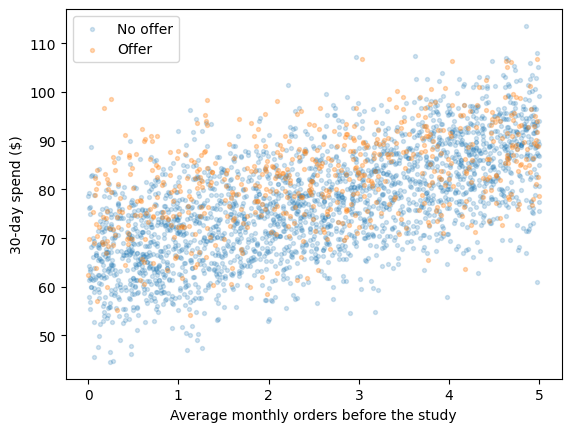

In [8]:
# Check the unit, available inputs, and assignment counts before fitting.
print(data.head(6).round(2).to_string(index=False))
rows = []
for name, ids in [("Training", train), ("Validation", validation), ("Test", test)]:
    rows.append({"Split": name, "Customers": len(ids),
                 "Offered": int(T[ids].sum()), "No offer": int((1-T[ids]).sum())})
# Plot observed outcomes, not individual effects set in the data setup.
plt.scatter(X[train][T[train]==0, 0], Y[train][T[train]==0], s=8, alpha=.2, label="No offer")
plt.scatter(X[train][T[train]==1, 0], Y[train][T[train]==1], s=8, alpha=.3, label="Offer")
plt.xlabel("Average monthly orders before the study")
plt.ylabel("30-day spend ($)")
plt.legend()

In [10]:
rows

[{'Split': 'Training', 'Customers': 3000, 'Offered': 580, 'No offer': 2420},
 {'Split': 'Validation', 'Customers': 1500, 'Offered': 318, 'No offer': 1182},
 {'Split': 'Test', 'Customers': 1500, 'Offered': 312, 'No offer': 1188}]

In [12]:
df = pd.DataFrame(rows)
print(df.to_string(index=False))

     Split  Customers  Offered  No offer
  Training       3000      580      2420
Validation       1500      318      1182
      Test       1500      312      1188


The training sample contains 580 offered and 2,420 unoffered customers. That imbalance is intentional, not evidence that randomization failed. The test set keeps another 312 offered customers untouched.

The scatter shows that people with more prior orders generally spend more. It does not tell us which profiles benefit most from the offer. That requires predicting both outcomes for the same profile.

#### 2. Fit one outcome model, then two

Start with S and T on the same training customers. EconML's effect method does the two-prediction subtraction. We use three customer profiles as a readable check, holding prior discount use at 50%.

In [17]:
# S uses one model; T estimates a separate outcome model for each arm.
s = SLearner(overall_model=outcome_model())
t = TLearner(models=outcome_model())
s.fit(Y[train], T[train], X=X[train])
t.fit(Y[train], T[train], X=X[train])
# Hold discount history constant while comparing customer profiles.
profiles = np.array([[0.5, .5], [2.5, .5], [4.5, .5]])
effects = pd.DataFrame({
    "Prior orders": profiles[:, 0],
    "S: predicted offer effect ($)": s.effect(profiles),
    "T: predicted offer effect ($)": t.effect(profiles),
}).round(2)

print(effects.to_string(index=False))

 Prior orders  S: predicted offer effect ($)  T: predicted offer effect ($)
          0.5                           8.30                          10.42
          2.5                           4.24                           6.22
          4.5                           1.41                           1.13


For a customer averaging 0.5 earlier orders per month, S predicts $8.30 in extra spending and T predicts $10.42. At 4.5 earlier orders, their predictions fall to $1.41 and $1.13. Both suggest that frequent shoppers need the offer less, even though they spend more overall.

These are predicted increases in 30-day spending, not total spending. S and T differ because one shares a model and the other fits each arm separately. Do not pick a winner from three plausible-looking predictions. Next we check the effect pattern outside training.